# Raw amplitude exploration

Load multiple sessions and compare one accepted attempt of the same scenario per session. Amplitude is the magnitude of the recorded I/Q values, without scaling, filtering or resampling. Invalid packets and unusable HE20 subcarriers are masked by the shared decoder.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "fall_detection").is_dir()
)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from fall_detection.analysis.amplitude_pipeline import (
    AmplitudePacketReader, load_amplitude_session, prepare_recording,
)

# Add or remove IDs here; each session is loaded independently.
SESSION_IDS = ["20261104T081805521126Z", "20261109T131546367822Z"]
if not SESSION_IDS or len(set(SESSION_IDS)) != len(SESSION_IDS):
    raise ValueError("Select at least one distinct session ID.")
sessions = {
    session_id: load_amplitude_session(
        PROJECT_ROOT / "data/raw/sessions" / f"{session_id}.zip",
        PROJECT_ROOT / "data/interim/parquet" / session_id,
    )
    for session_id in SESSION_IDS
}
attempts = pd.concat(
    [session.attempts.to_pandas() for session in sessions.values()], ignore_index=True
)
display(attempts.groupby(["participant_id", "session_id"], dropna=False)
        .size().rename("attempts").reset_index())

,participant_id,session_id,attempts
0,akmal,20261109T131546367822Z,246
1,khaelano,20261104T081805521126Z,255


## Compare a shared scenario

Choose a scenario ID and optionally an exact attempt key for each session. By default the first accepted, non-excluded attempt that is not marked bad is selected in each session. Matching the scenario does not make the movement or recording conditions identical. Times are relative to each attempt's action cue, not a measured movement onset.

In [2]:
SCENARIO_ID = "walk-to-fall__start_front__end_front"
# Optional overrides: {"session_id": "trials/.../attempt_01"}.
ATTEMPT_KEYS = {}
RECEIVER_IDS = ["rx-1", "rx-2", "rx-3", "rx-4"]
# Signed physical HE20 subcarrier indices; change these to inspect other tones.
SUBCARRIERS = [-100, -50, 20, 100]

selected = []
for session_id in SESSION_IDS:
    candidates = attempts.loc[
        attempts["session_id"].eq(session_id)
        & attempts["scenario_id"].eq(SCENARIO_ID)
        & attempts["status"].eq("accepted")
        & attempts["inclusion"].ne("exclude")
        & attempts["quality"].ne("bad")
    ].sort_values(["trial_ordinal", "attempt"])
    if session_id in ATTEMPT_KEYS:
        candidates = candidates.loc[candidates["attempt_key"].eq(ATTEMPT_KEYS[session_id])]
    if candidates.empty:
        raise ValueError(f"No eligible attempt for {session_id} / {SCENARIO_ID}")
    selected.append(candidates.iloc[0])
selected_attempts = pd.DataFrame(selected).reset_index(drop=True)
display(selected_attempts[[
    "participant_id", "session_id", "scenario_id", "attempt_id",
    "attempt_key", "repetition", "quality",
]])

,participant_id,session_id,scenario_id,attempt_id,attempt_key,repetition,quality
0,khaelano,20261104T081805521126Z,walk-to-fall__start_front__end_front,169/01,trials/169_walk-to-fall__start_front__end_fron...,1,unreviewed
1,akmal,20261109T131546367822Z,walk-to-fall__start_front__end_front,169/01,trials/169_walk-to-fall__start_front__end_fron...,1,unreviewed


In [ ]:
recordings = {}
for row in selected_attempts.itertuples(index=False):
    session = sessions[row.session_id]
    phases = pd.read_parquet(session.path / "phases.parquet")
    action = phases.loc[
        phases["attempt_key"].eq(row.attempt_key)
        & phases["collection_phase"].eq("action")
    ]
    if len(action) != 1:
        raise ValueError(f"Expected one action cue for {row.attempt_key}")
    cue_ns = int(action.iloc[0]["start_ns"])
    reader = AmplitudePacketReader(session.path / "packets.parquet")
    try:
        for receiver_id in RECEIVER_IDS:
            recording = prepare_recording(reader.read(row.attempt_key, receiver_id))
            if not set(SUBCARRIERS).issubset(set(recording.subcarriers)):
                raise ValueError("Requested subcarrier outside the HE20 range.")
            recordings[row.session_id, receiver_id] = {
                "participant": row.participant_id,
                "recording": recording,
                "time": (recording.metadata["capture_time_ns"].to_numpy() - cue_ns) / 1e9,
            }
    finally:
        reader.close()

Each row is a receiver and each column a signed physical subcarrier. Lines show individual recorded packets; masked values break lines; missing packets are not reconstructed and adjacent available packets are joined. The common vertical scale supports comparison across panels, but raw amplitude can also reflect radio gain and placement.

Raw CSI amplitude · walk-to-fall__start_front__end_front


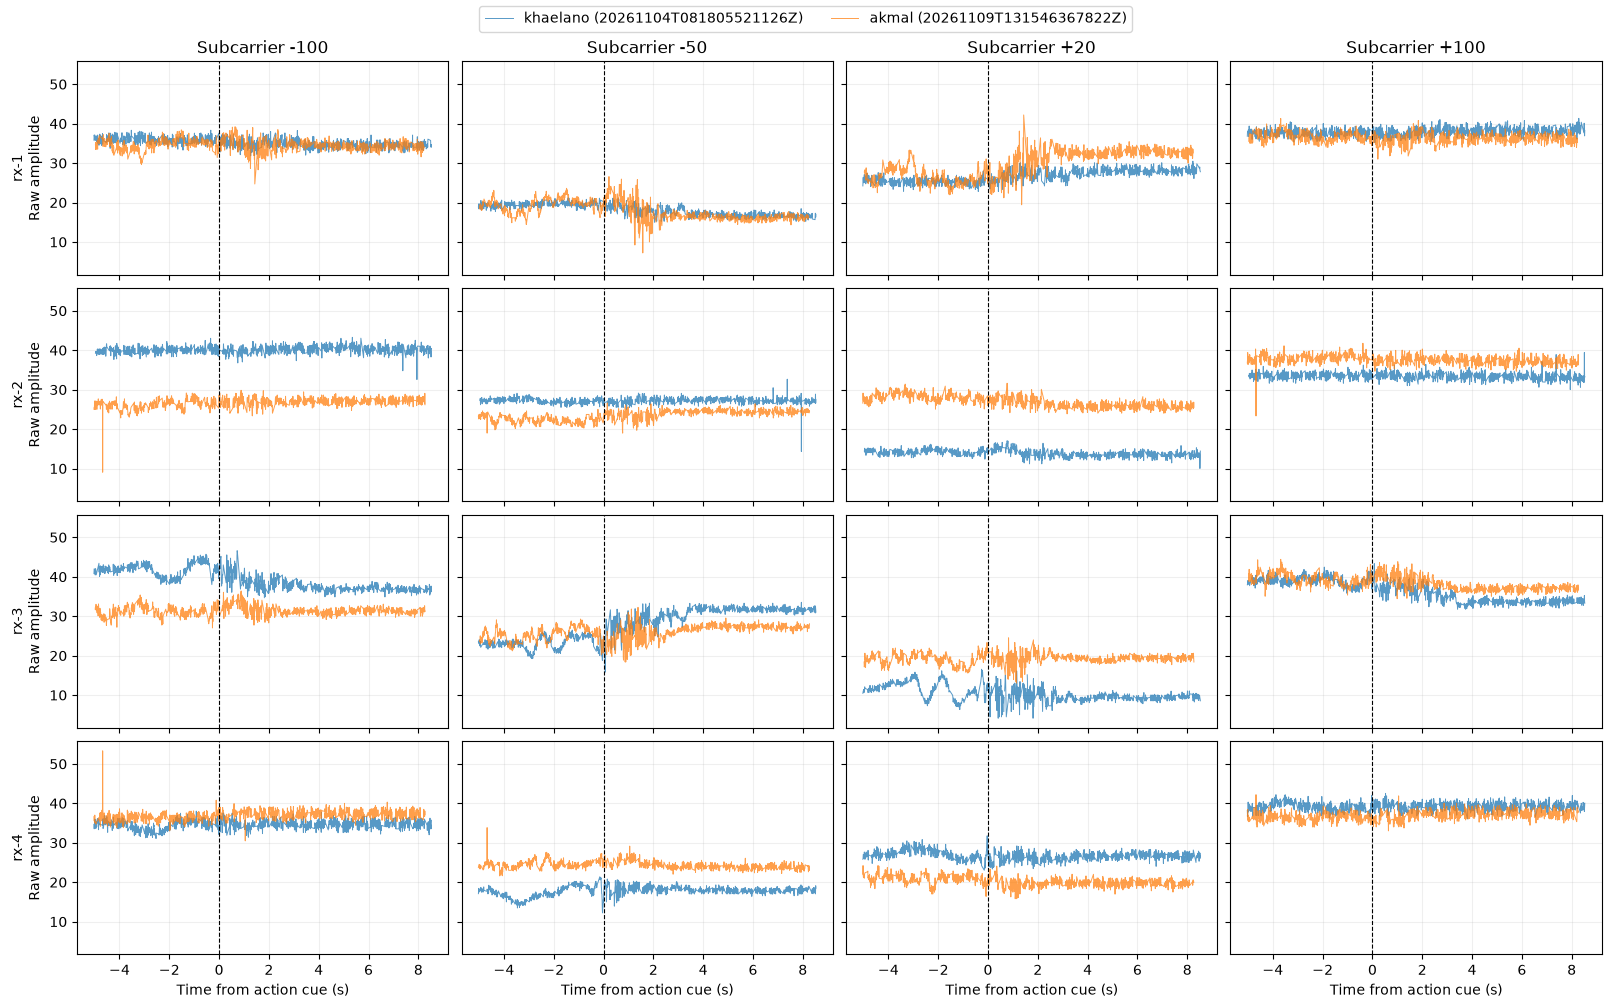

Saved: /home/khaelano/Projects/radio-fall-detection/docs/figures/raw-amplitude-session-comparison.png


In [5]:
fig, axes = plt.subplots(
    len(RECEIVER_IDS), len(SUBCARRIERS),
    figsize=(4 * len(SUBCARRIERS), 2.5 * len(RECEIVER_IDS)),
    sharex=True, sharey=True, squeeze=False, layout="constrained",
)
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, receiver_id in enumerate(RECEIVER_IDS):
    for j, tone in enumerate(SUBCARRIERS):
        ax = axes[i, j]
        for k, session_id in enumerate(SESSION_IDS):
            sample = recordings[session_id, receiver_id]
            recording = sample["recording"]
            index = int(np.flatnonzero(recording.subcarriers == tone)[0])
            ax.plot(sample["time"], recording.masked[:, index], lw=0.7, alpha=0.75,
                    color=colors[k % len(colors)],
                    label=f'{sample["participant"]} ({session_id})')
        ax.axvline(0, color="black", ls="--", lw=0.8)
        ax.grid(alpha=0.2)
        if i == 0:
            ax.set_title(f"Subcarrier {tone:+d}")
        if j == 0:
            ax.set_ylabel(f"{receiver_id}\nRaw amplitude")
        if i == len(RECEIVER_IDS) - 1:
            ax.set_xlabel("Time from action cue (s)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=2)
print(f"Raw CSI amplitude · {SCENARIO_ID}")
output_path = PROJECT_ROOT / "docs/figures/raw-amplitude-session-comparison.png"
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=150)
plt.show()
print(f"Saved: {output_path}")

## Squared consecutive amplitude difference

For each receiver and subcarrier, $\Delta A_t = (a_t-a_{t-1})^2$ compares consecutive recorded sensing packets and is plotted at the later packet's capture time. A masked reading also masks its adjacent differences. Packet intervals may vary or span missing packets; this is not a time-normalized rate of change.

Squared consecutive amplitude difference · walk-to-fall__start_front__end_front


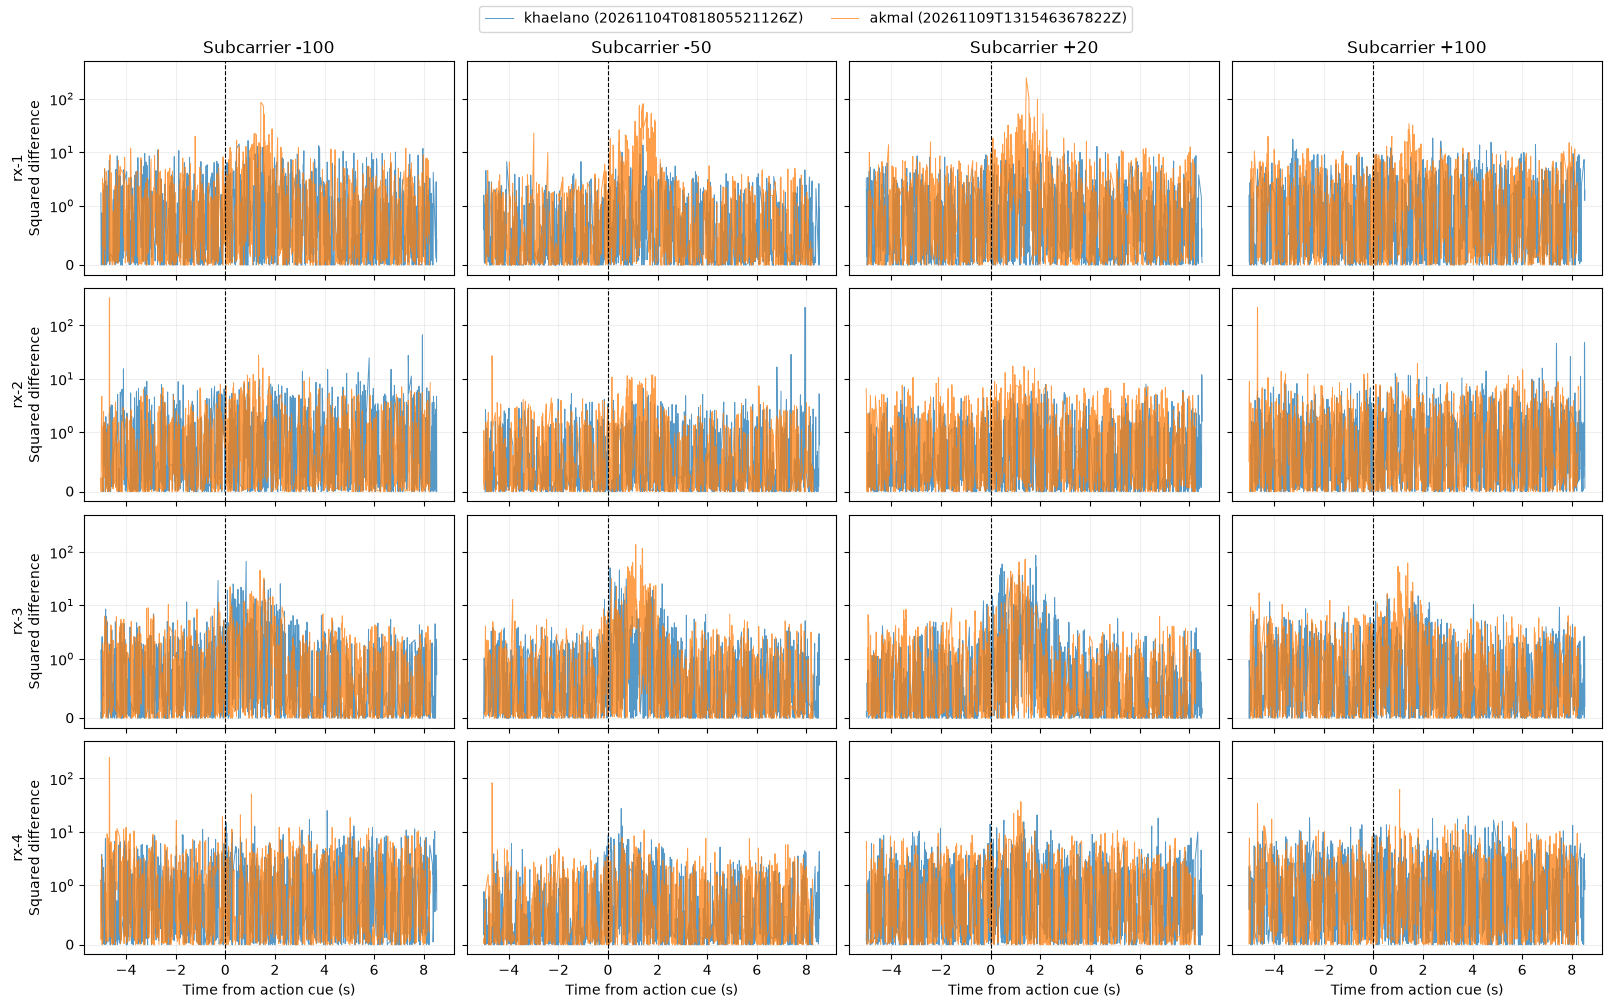

Saved: /home/khaelano/Projects/radio-fall-detection/docs/figures/squared-amplitude-difference-comparison.png


In [6]:
fig, axes = plt.subplots(
    len(RECEIVER_IDS), len(SUBCARRIERS),
    figsize=(4 * len(SUBCARRIERS), 2.5 * len(RECEIVER_IDS)),
    sharex=True, sharey=True, squeeze=False, layout="constrained",
)
for i, receiver_id in enumerate(RECEIVER_IDS):
    for j, tone in enumerate(SUBCARRIERS):
        ax = axes[i, j]
        for k, session_id in enumerate(SESSION_IDS):
            sample = recordings[session_id, receiver_id]
            recording = sample["recording"]
            index = int(np.flatnonzero(recording.subcarriers == tone)[0])
            amplitude = recording.masked[:, index]
            delta = np.diff(amplitude) ** 2
            ax.plot(sample["time"][1:], delta, lw=0.7, alpha=0.75,
                    color=colors[k % len(colors)],
                    label=f'{sample["participant"]} ({session_id})')
        ax.axvline(0, color="black", ls="--", lw=0.8)
        # The linear region includes zero; the logarithmic region reveals spikes.
        ax.set_yscale("symlog", linthresh=1)
        ax.grid(alpha=0.2)
        if i == 0:
            ax.set_title(f"Subcarrier {tone:+d}")
        if j == 0:
            ax.set_ylabel(f"{receiver_id}\nSquared difference")
        if i == len(RECEIVER_IDS) - 1:
            ax.set_xlabel("Time from action cue (s)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=2)
print(f"Squared consecutive amplitude difference · {SCENARIO_ID}")
difference_path = PROJECT_ROOT / "docs/figures/squared-amplitude-difference-comparison.png"
difference_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(difference_path, dpi=150)
plt.show()
print(f"Saved: {difference_path}")

## Hampel-filtered raw amplitude

Apply the Hampel filter independently to each receiver and subcarrier, before any scaling. The centered 0.1-second window uses at least five finite readings; values more than five scaled median absolute deviations from the local median are replaced. Zero-MAD windows are left unchanged. The filter uses future samples, retains masked readings, and does not fill missing packets. Parameters below are exploratory.

In [16]:
from fall_detection.analysis.amplitude import hampel_subcarriers

HAMPEL_WINDOW_SECONDS = 0.1
HAMPEL_MIN_PERIODS = 5
HAMPEL_THRESHOLD = 5.0

filtered_recordings = {}
replacement_masks = {}
replacement_summary = []
for (session_id, receiver_id), sample in recordings.items():
    recording = sample["recording"]
    filtered, replaced = hampel_subcarriers(
        recording.masked, sample["time"],
        window_seconds=HAMPEL_WINDOW_SECONDS,
        min_periods=HAMPEL_MIN_PERIODS,
        threshold=HAMPEL_THRESHOLD,
    )
    filtered_recordings[session_id, receiver_id] = filtered
    replacement_masks[session_id, receiver_id] = replaced
    for tone in SUBCARRIERS:
        index = int(np.flatnonzero(recording.subcarriers == tone)[0])
        replacement_summary.append({
            "participant": sample["participant"], "session_id": session_id,
            "receiver": receiver_id, "subcarrier": tone,
            "valid_readings": int(np.isfinite(recording.masked[:, index]).sum()),
            "replaced": int(replaced[:, index].sum()),
        })
display(pd.DataFrame(replacement_summary))

,participant,session_id,receiver,subcarrier,valid_readings,replaced
0,khaelano,20261104T081805521126Z,rx-1,-100,1337,6
1,khaelano,20261104T081805521126Z,rx-1,-50,1337,5
2,khaelano,20261104T081805521126Z,rx-1,20,1337,8
3,khaelano,20261104T081805521126Z,rx-1,100,1337,12
4,khaelano,20261104T081805521126Z,rx-2,-100,1344,9
5,khaelano,20261104T081805521126Z,rx-2,-50,1344,11
6,khaelano,20261104T081805521126Z,rx-2,20,1344,9
7,khaelano,20261104T081805521126Z,rx-2,100,1344,9
8,khaelano,20261104T081805521126Z,rx-3,-100,1339,4
9,khaelano,20261104T081805521126Z,rx-3,-50,1339,6


Hampel-filtered raw CSI amplitude · walk-to-fall__start_front__end_front


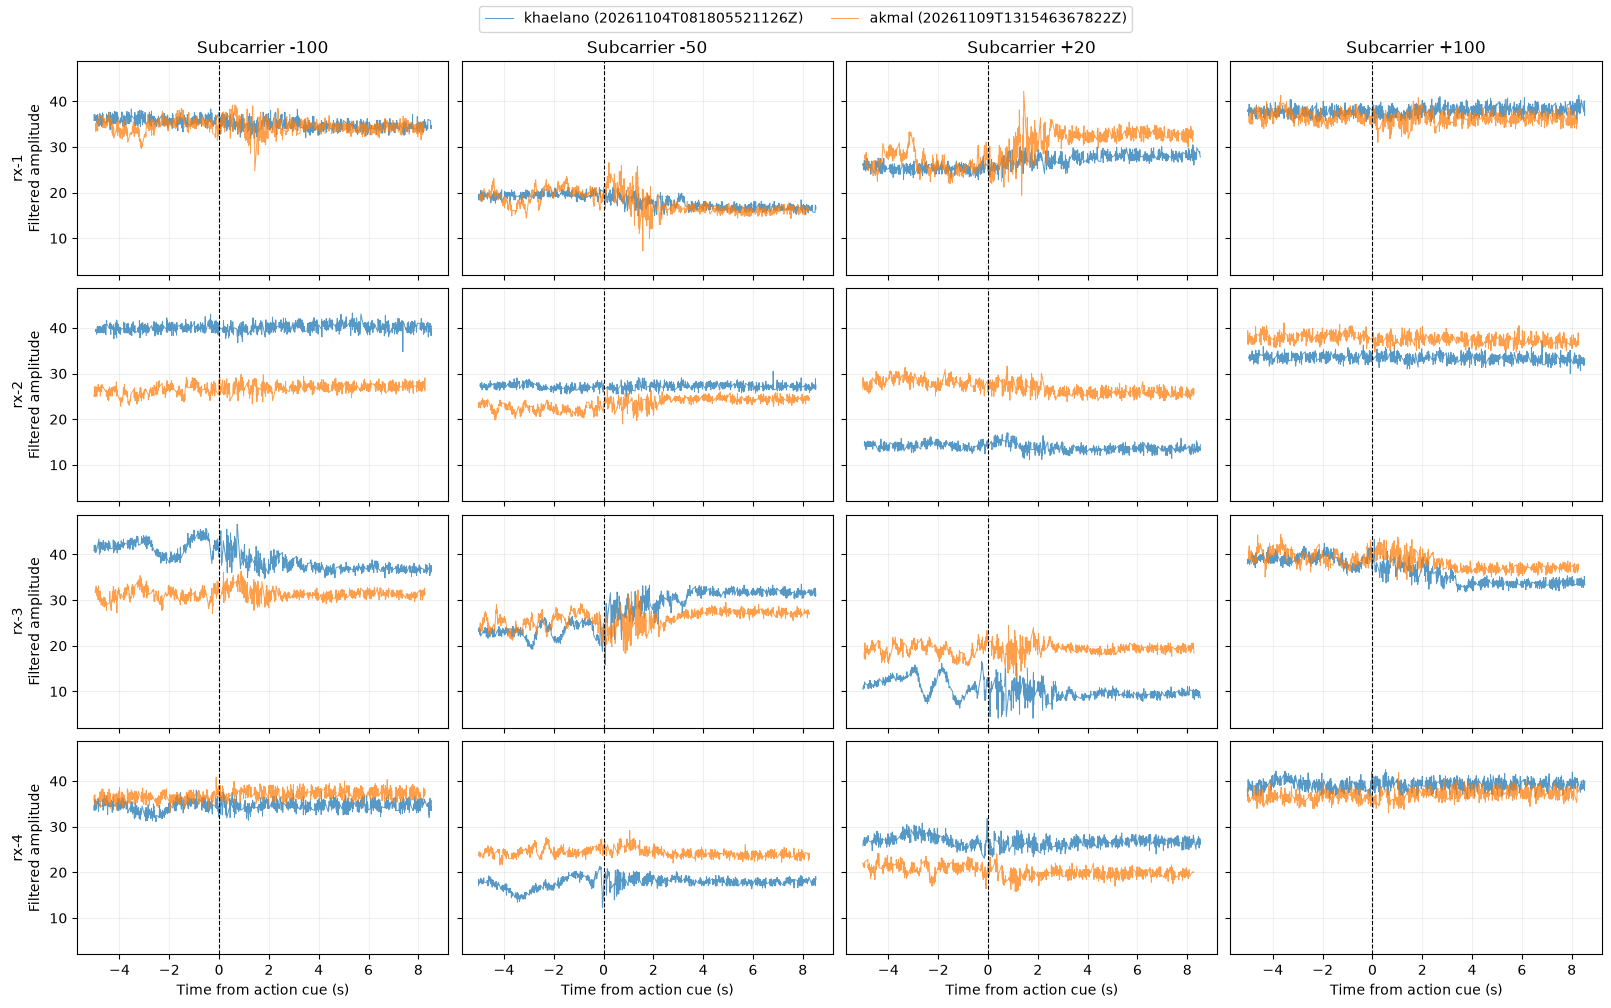

Saved: /home/khaelano/Projects/radio-fall-detection/docs/figures/hampel-amplitude-session-comparison.png


In [8]:
fig, axes = plt.subplots(
    len(RECEIVER_IDS), len(SUBCARRIERS),
    figsize=(4 * len(SUBCARRIERS), 2.5 * len(RECEIVER_IDS)),
    sharex=True, sharey=True, squeeze=False, layout="constrained",
)
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, receiver_id in enumerate(RECEIVER_IDS):
    for j, tone in enumerate(SUBCARRIERS):
        ax = axes[i, j]
        for k, session_id in enumerate(SESSION_IDS):
            sample = recordings[session_id, receiver_id]
            index = int(np.flatnonzero(sample["recording"].subcarriers == tone)[0])
            ax.plot(sample["time"], filtered_recordings[session_id, receiver_id][:, index],
                    lw=0.7, alpha=0.75, color=colors[k % len(colors)],
                    label=f'{sample["participant"]} ({session_id})')
        ax.axvline(0, color="black", ls="--", lw=0.8)
        ax.grid(alpha=0.2)
        if i == 0:
            ax.set_title(f"Subcarrier {tone:+d}")
        if j == 0:
            ax.set_ylabel(f"{receiver_id}\nFiltered amplitude")
        if i == len(RECEIVER_IDS) - 1:
            ax.set_xlabel("Time from action cue (s)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=2)
print(f"Hampel-filtered raw CSI amplitude · {SCENARIO_ID}")
hampel_path = PROJECT_ROOT / "docs/figures/hampel-amplitude-session-comparison.png"
hampel_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(hampel_path, dpi=150)
plt.show()
print(f"Saved: {hampel_path}")

## Squared difference after Hampel filtering

Compute $(\widetilde a_t - \widetilde a_{t-1})^2$ from the filtered amplitudes above and assign each result to the later packet's time. As in the raw difference plot, packet intervals can vary or span missing packets, and masked readings mask adjacent differences. The centered filter uses future samples.

Squared amplitude difference after Hampel filtering · walk-to-fall__start_front__end_front


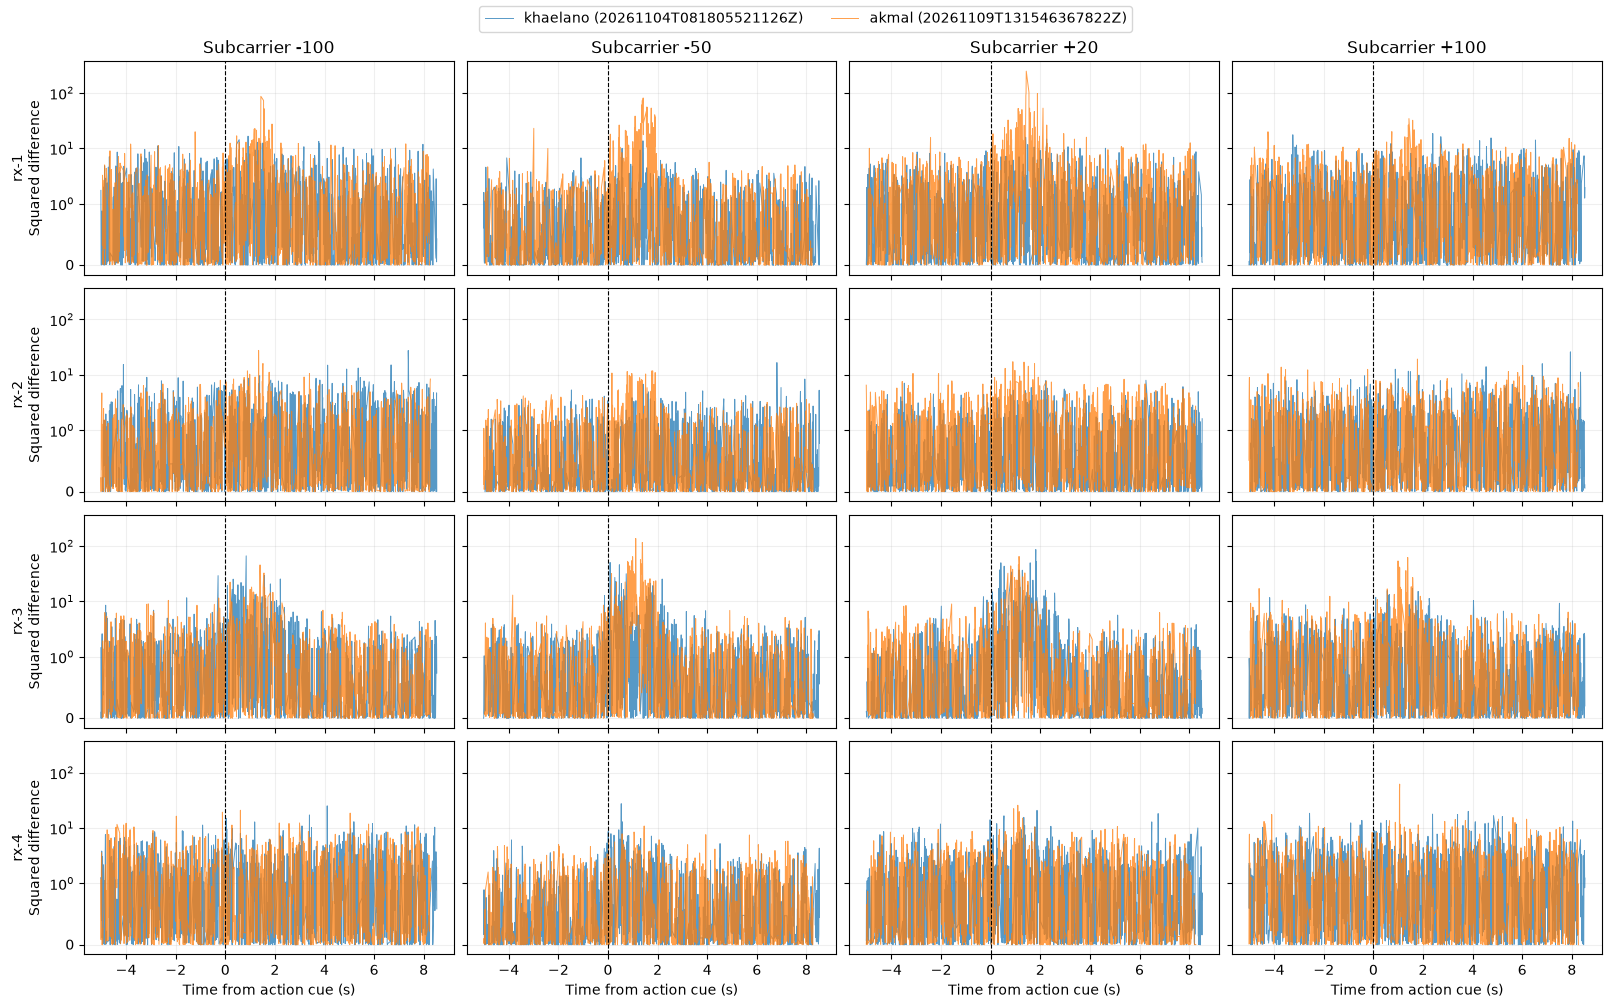

Saved: /home/khaelano/Projects/radio-fall-detection/docs/figures/hampel-squared-difference-comparison.png


In [9]:
fig, axes = plt.subplots(
    len(RECEIVER_IDS), len(SUBCARRIERS),
    figsize=(4 * len(SUBCARRIERS), 2.5 * len(RECEIVER_IDS)),
    sharex=True, sharey=True, squeeze=False, layout="constrained",
)
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, receiver_id in enumerate(RECEIVER_IDS):
    for j, tone in enumerate(SUBCARRIERS):
        ax = axes[i, j]
        for k, session_id in enumerate(SESSION_IDS):
            sample = recordings[session_id, receiver_id]
            index = int(np.flatnonzero(sample["recording"].subcarriers == tone)[0])
            amplitude = filtered_recordings[session_id, receiver_id][:, index]
            delta = np.diff(amplitude) ** 2
            ax.plot(sample["time"][1:], delta, lw=0.7, alpha=0.75,
                    color=colors[k % len(colors)],
                    label=f'{sample["participant"]} ({session_id})')
        ax.axvline(0, color="black", ls="--", lw=0.8)
        ax.set_yscale("symlog", linthresh=1)
        ax.grid(alpha=0.2)
        if i == 0:
            ax.set_title(f"Subcarrier {tone:+d}")
        if j == 0:
            ax.set_ylabel(f"{receiver_id}\nSquared difference")
        if i == len(RECEIVER_IDS) - 1:
            ax.set_xlabel("Time from action cue (s)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=2)
print(f"Squared amplitude difference after Hampel filtering · {SCENARIO_ID}")
filtered_difference_path = PROJECT_ROOT / "docs/figures/hampel-squared-difference-comparison.png"
filtered_difference_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(filtered_difference_path, dpi=150)
plt.show()
print(f"Saved: {filtered_difference_path}")

## Pearson correlation of squared differences

For each selected session, receiver and subcarrier, let $x_t=(a_t-a_{t-1})^2$ and $y_t=(\widetilde a_t-\widetilde a_{t-1})^2$, where $\widetilde a$ is the Hampel-filtered amplitude. Pearson's coefficient is $r=\frac{\sum_t (x_t-\bar{x})(y_t-\bar{y})}{\sqrt{\sum_t (x_t-\bar{x})^2\sum_t (y_t-\bar{y})^2}}$, using only pairs where both values are finite. A coefficient is undefined when fewer than two pairs remain or either series is constant. Correlation measures linear association, not equality, and may be dominated by spikes.

In [10]:
correlation_rows = []
for session_id in SESSION_IDS:
    for receiver_id in RECEIVER_IDS:
        sample = recordings[session_id, receiver_id]
        recording = sample["recording"]
        for tone in SUBCARRIERS:
            index = int(np.flatnonzero(recording.subcarriers == tone)[0])
            raw_difference = np.diff(recording.masked[:, index]) ** 2
            filtered_difference = np.diff(filtered_recordings[session_id, receiver_id][:, index]) ** 2
            valid = np.isfinite(raw_difference) & np.isfinite(filtered_difference)
            x, y = raw_difference[valid], filtered_difference[valid]
            if len(x) < 2:
                correlation = np.nan
            else:
                x_centered, y_centered = x - x.mean(), y - y.mean()
                denominator = np.sqrt(np.sum(x_centered ** 2) * np.sum(y_centered ** 2))
                correlation = (
                    float(np.sum(x_centered * y_centered) / denominator)
                    if denominator > 0 else np.nan
                )
            correlation_rows.append({
                "participant": sample["participant"], "session_id": session_id,
                "receiver": receiver_id, "subcarrier": tone,
                "paired_readings": len(x), "pearson_r": correlation,
            })
difference_correlations = pd.DataFrame(correlation_rows)
display(difference_correlations)

,participant,session_id,receiver,subcarrier,paired_readings,pearson_r
0,khaelano,20261104T081805521126Z,rx-1,-100,1336,0.980950
1,khaelano,20261104T081805521126Z,rx-1,-50,1336,0.993439
2,khaelano,20261104T081805521126Z,rx-1,20,1336,0.954867
3,khaelano,20261104T081805521126Z,rx-1,100,1336,0.958242
4,khaelano,20261104T081805521126Z,rx-2,-100,1343,0.616305
5,khaelano,20261104T081805521126Z,rx-2,-50,1343,0.193101
6,khaelano,20261104T081805521126Z,rx-2,20,1343,0.904917
7,khaelano,20261104T081805521126Z,rx-2,100,1343,0.634787
8,khaelano,20261104T081805521126Z,rx-3,-100,1338,0.978239
9,khaelano,20261104T081805521126Z,rx-3,-50,1338,0.999317


## Squared differences with Pearson correlation below 0.5

Each panel compares the unfiltered and Hampel-filtered squared differences for one selected session, receiver and subcarrier. The selection excludes undefined correlations; the symmetric logarithmic scale shows zero and larger spikes.

,participant,session_id,receiver,subcarrier,paired_readings,pearson_r
0,khaelano,20261104T081805521126Z,rx-2,-50,1343,0.193101
1,akmal,20261109T131546367822Z,rx-2,-100,1319,0.118984
2,akmal,20261109T131546367822Z,rx-2,100,1319,0.221860
3,akmal,20261109T131546367822Z,rx-4,-100,1289,0.229247
4,akmal,20261109T131546367822Z,rx-4,-50,1289,0.307899


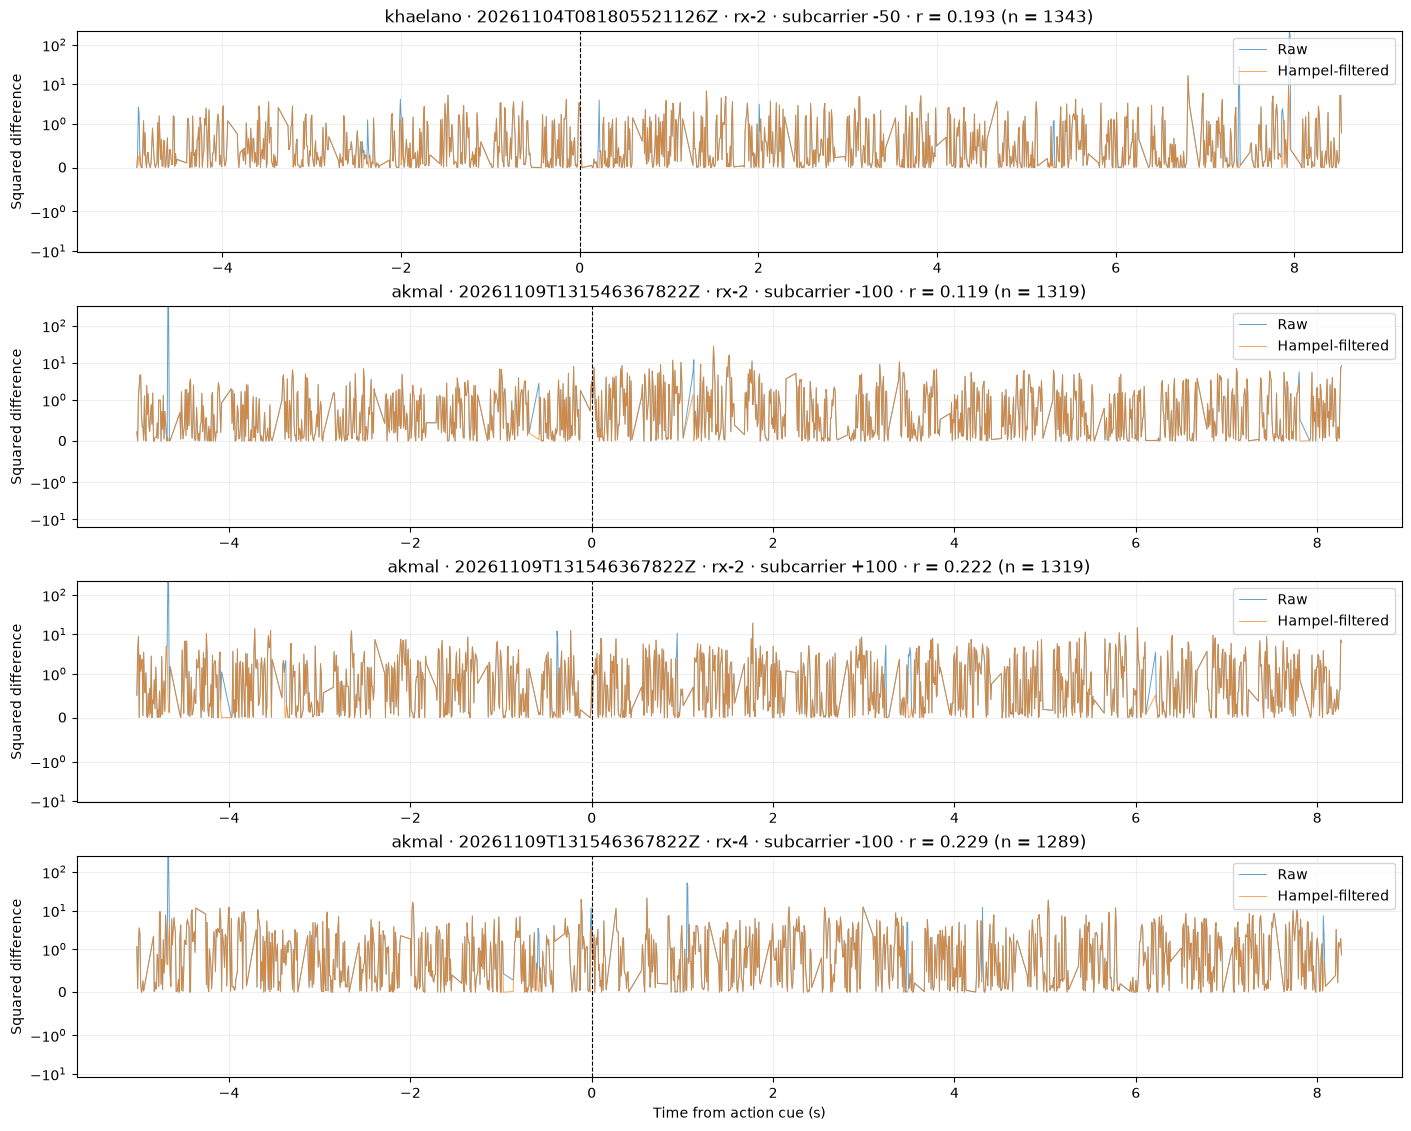

Saved: /home/khaelano/Projects/radio-fall-detection/docs/figures/low-correlation-squared-differences-1.png


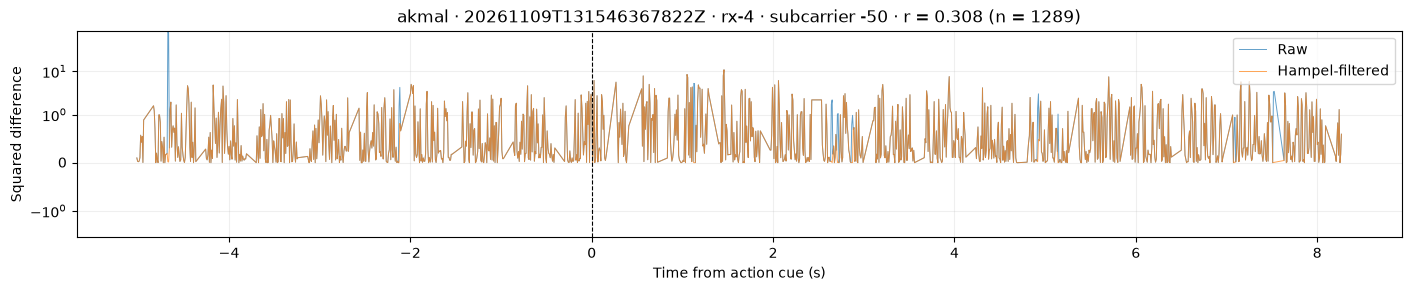

Saved: /home/khaelano/Projects/radio-fall-detection/docs/figures/low-correlation-squared-differences-2.png


In [11]:
CORRELATION_CUTOFF = 0.5
low_correlations = difference_correlations.loc[
    difference_correlations["pearson_r"].lt(CORRELATION_CUTOFF)
].reset_index(drop=True)
display(low_correlations)

if low_correlations.empty:
    print(f"No defined correlations below {CORRELATION_CUTOFF}.")
else:
    # Limit each figure to four panels so each trace remains readable.
    for start in range(0, len(low_correlations), 4):
        group = low_correlations.iloc[start:start + 4]
        fig, axes = plt.subplots(
            len(group), 1, figsize=(14, 2.8 * len(group)),
            squeeze=False, layout="constrained",
        )
        for ax, row in zip(axes[:, 0], group.itertuples(index=False)):
            sample = recordings[row.session_id, row.receiver]
            recording = sample["recording"]
            index = int(np.flatnonzero(recording.subcarriers == row.subcarrier)[0])
            raw = np.diff(recording.masked[:, index]) ** 2
            filtered = np.diff(filtered_recordings[row.session_id, row.receiver][:, index]) ** 2
            ax.plot(sample["time"][1:], raw, lw=0.7, alpha=0.7, label="Raw")
            ax.plot(sample["time"][1:], filtered, lw=0.7, alpha=0.7, label="Hampel-filtered")
            ax.axvline(0, color="black", ls="--", lw=0.8)
            ax.set_yscale("symlog", linthresh=1)
            ax.set_ylabel("Squared difference")
            ax.set_title(
                f"{row.participant} · {row.session_id} · {row.receiver} · "
                f"subcarrier {row.subcarrier:+d} · r = {row.pearson_r:.3f} "
                f"(n = {row.paired_readings})"
            )
            ax.grid(alpha=0.2)
            ax.legend(loc="upper right")
        axes[-1, 0].set_xlabel("Time from action cue (s)")
        low_corr_path = PROJECT_ROOT / "docs/figures" / (
            f"low-correlation-squared-differences-{start // 4 + 1}.png"
        )
        low_corr_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(low_corr_path, dpi=150)
        plt.show()
        print(f"Saved: {low_corr_path}")

## Close-ups of Hampel replacements

The default examples are the two largest absolute replacements per session among the selected receivers and subcarriers; they are illustrative, not a random sample. Each panel shows the raw and filtered traces around one selected replacement, with all replacements in that window marked. Change `EXAMPLES_PER_SESSION` and `ZOOM_HALF_SECONDS` to inspect more context. A flagged point is not necessarily a measurement error.

,participant,session_id,receiver,subcarrier,time,raw,filtered,absolute_change
0,akmal,20261109T131546367822Z,rx-2,-100,-4.674239,9.055385,26.925824,17.870439
1,akmal,20261109T131546367822Z,rx-4,-100,-4.674239,53.310412,36.783146,16.527266
2,khaelano,20261104T081805521126Z,rx-2,-50,7.942450,14.317821,27.018512,12.700691
3,khaelano,20261104T081805521126Z,rx-2,-100,7.942450,32.557641,40.484548,7.926907


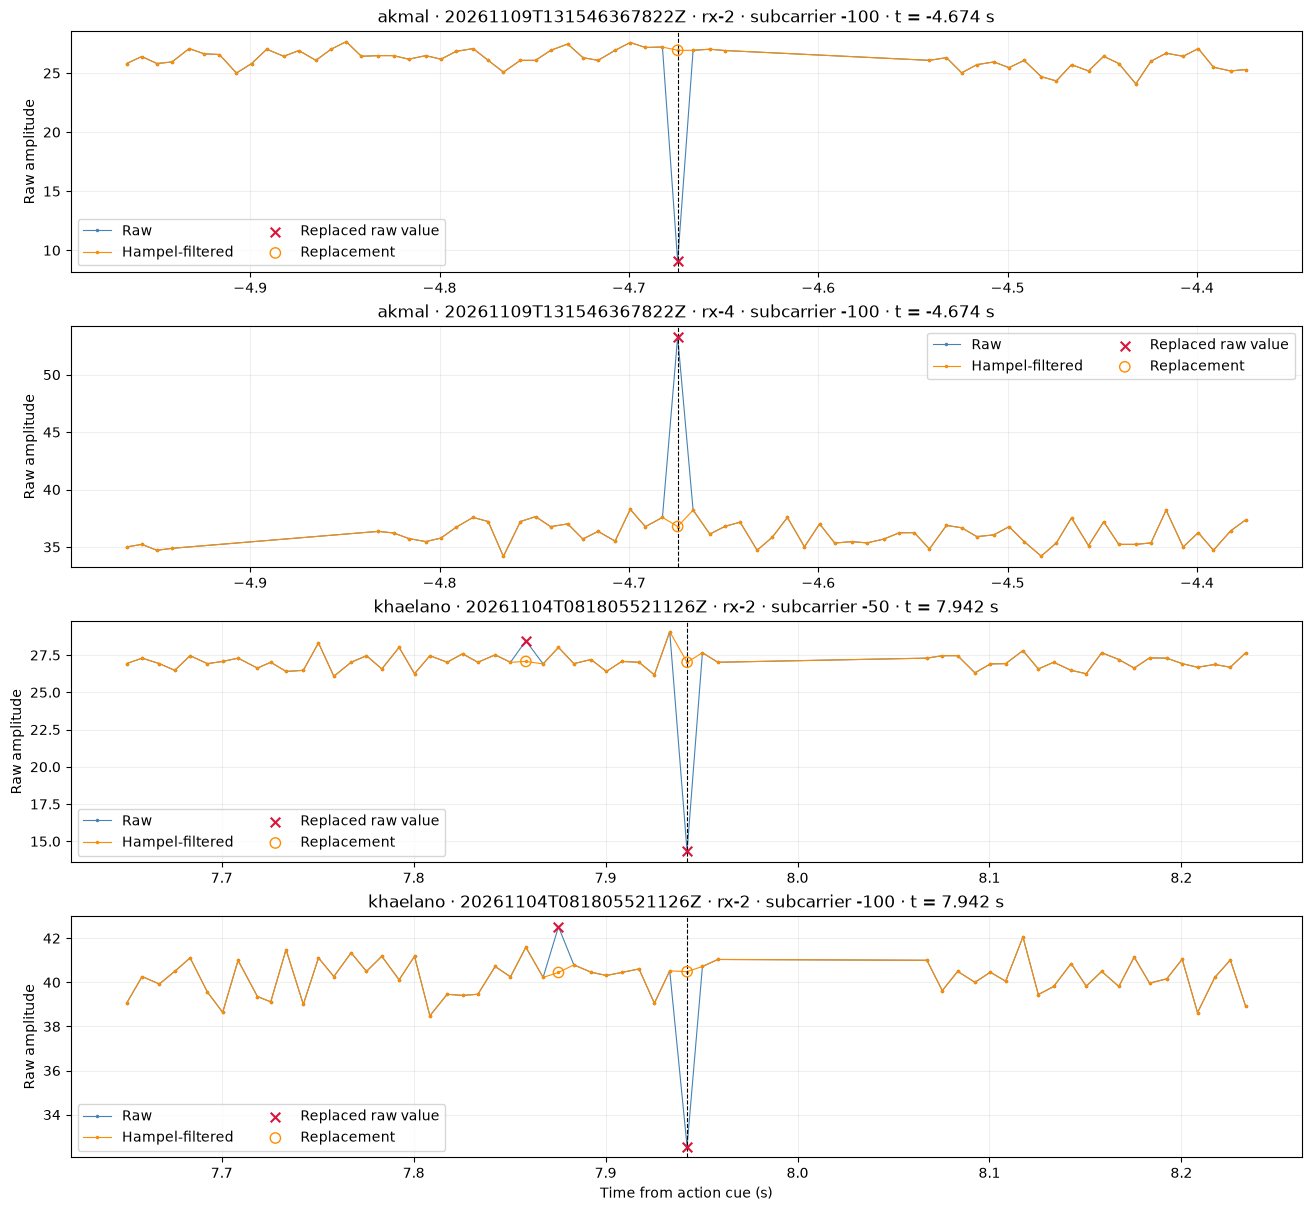

Saved: /home/khaelano/Projects/radio-fall-detection/docs/figures/hampel-replacement-closeups.png


In [17]:
EXAMPLES_PER_SESSION = 2
ZOOM_HALF_SECONDS = 0.3

replacement_events = []
for session_id in SESSION_IDS:
    for receiver_id in RECEIVER_IDS:
        sample = recordings[session_id, receiver_id]
        recording = sample["recording"]
        for tone in SUBCARRIERS:
            index = int(np.flatnonzero(recording.subcarriers == tone)[0])
            for row in np.flatnonzero(replacement_masks[session_id, receiver_id][:, index]):
                raw = recording.masked[row, index]
                filtered = filtered_recordings[session_id, receiver_id][row, index]
                replacement_events.append({
                    "participant": sample["participant"], "session_id": session_id,
                    "receiver": receiver_id, "subcarrier": tone, "row": int(row),
                    "time": float(sample["time"][row]), "raw": float(raw),
                    "filtered": float(filtered), "absolute_change": float(abs(raw - filtered)),
                })
event_columns = ["participant", "session_id", "receiver", "subcarrier", "row",
                 "time", "raw", "filtered", "absolute_change"]
replacement_events = pd.DataFrame(replacement_events, columns=event_columns)
examples = (replacement_events.sort_values("absolute_change", ascending=False)
            .groupby("session_id", sort=False, group_keys=False)
            .head(EXAMPLES_PER_SESSION).reset_index(drop=True))
display(examples.drop(columns="row"))

if examples.empty:
    print("No replaced readings for the selected sessions, receivers and subcarriers.")
else:
    fig, axes = plt.subplots(len(examples), 1, figsize=(13, 3 * len(examples)),
                             squeeze=False, layout="constrained")
    for ax, event in zip(axes[:, 0], examples.itertuples(index=False)):
        sample = recordings[event.session_id, event.receiver]
        recording = sample["recording"]
        index = int(np.flatnonzero(recording.subcarriers == event.subcarrier)[0])
        time = sample["time"]
        within = np.abs(time - event.time) <= ZOOM_HALF_SECONDS
        marked = within & replacement_masks[event.session_id, event.receiver][:, index]
        raw = recording.masked[:, index]
        filtered = filtered_recordings[event.session_id, event.receiver][:, index]
        ax.plot(time[within], raw[within], ".-", color="steelblue", lw=0.8,
                ms=3, label="Raw")
        ax.plot(time[within], filtered[within], ".-", color="darkorange", lw=0.8,
                ms=3, label="Hampel-filtered")
        ax.scatter(time[marked], raw[marked], color="crimson", marker="x",
                   s=48, zorder=4, label="Replaced raw value")
        ax.scatter(time[marked], filtered[marked], facecolors="none", edgecolors="darkorange",
                   s=55, zorder=4, label="Replacement")
        ax.axvline(event.time, color="black", ls="--", lw=0.8)
        ax.set_title(f"{event.participant} · {event.session_id} · {event.receiver} · "
                     f"subcarrier {event.subcarrier:+d} · t = {event.time:.3f} s")
        ax.set_ylabel("Raw amplitude")
        ax.grid(alpha=0.2)
        ax.legend(loc="best", ncol=2)
    axes[-1, 0].set_xlabel("Time from action cue (s)")
    zoom_path = PROJECT_ROOT / "docs/figures/hampel-replacement-closeups.png"
    zoom_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(zoom_path, dpi=150)
    plt.show()
    print(f"Saved: {zoom_path}")